✅ Grid index loaded
CSV: /home/users/jianxing/New_final/ACI_gridpoint_index.csv
Total selected gridpoints: 290
  c1 -> Cluster 1: 120 gridpoints
  c5 -> Cluster 2: 170 gridpoints

✅ OP indices loaded
Index file: /home/users/jianxing/copy/optimal_constraint_13th_variable_indices_from_1M.dat
Number of samples: 5000
Number of unique samples: 5000
Min index: 405
Max index: 999775

✅ Final synthetic c1 (BC + Nd + AAOD) indices loaded
Index file: /gws/ssde/j25a/acure/jianxing/Variable/GAM_values/Step_5_synthetic_constraint/Step_1_GPE_constraint/05_candidate_indices/c1/combo_BC_Nd_AAOD/c1_combo_BC_Nd_AAOD_top1000_indices_from_1M.dat
Number of samples: 1000
Number of unique samples: 1000
Min index: 405
Max index: 997053

✅ Final synthetic c5 (AAOD + Nd) indices loaded
Index file: /gws/ssde/j25a/acure/jianxing/Variable/GAM_values/Step_5_synthetic_constraint/Step_1_GPE_constraint/05_candidate_indices/c5/combo_AAOD_Nd/c5_combo_AAOD_Nd_top1000_indices_from_1M.dat
Number of samples: 1000
Number of 

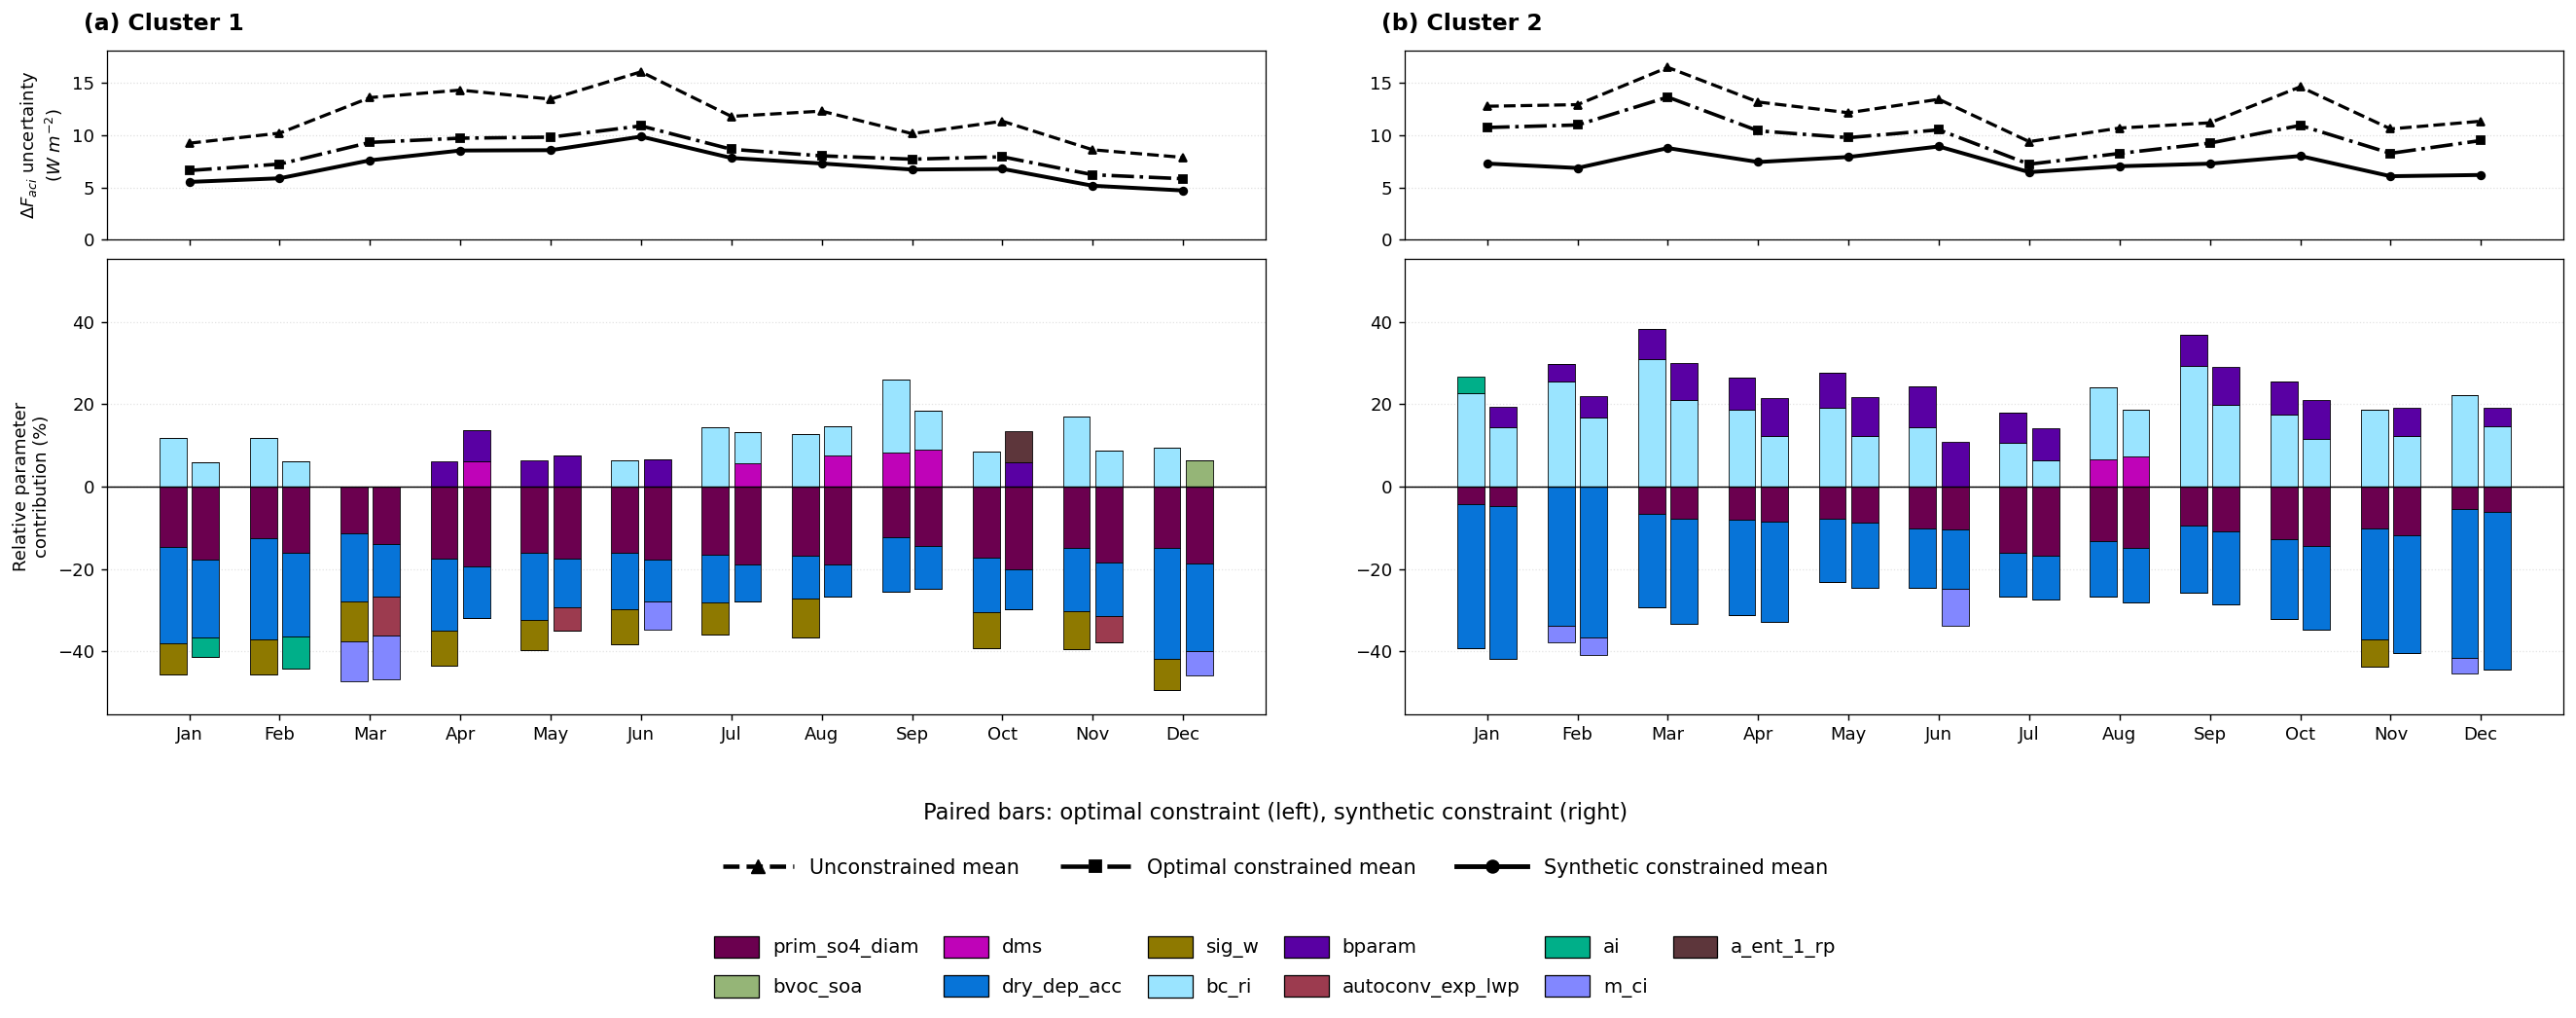

In [3]:
# ============================================================
# Final synthetic constrained ACI:
#
# Monthly uncertainty + monthly Top-4 parameter contributions
#
# Updated version:
#   1. Only Cluster 1 / c1 and Cluster 2 / c5 are included.
#   2. Two cluster panels are arranged horizontally (1 x 2).
#
# Upper panel of each cluster:
#   Three cluster-mean uncertainty lines:
#       a. Unconstrained 1M cluster-mean uncertainty
#       b. Remaining uncertainty after optimal constraint
#       c. Remaining uncertainty after final synthetic constraint
#
# Important:
#   The uncertainty definition is unchanged:
#
#       gridpoint CI90 = P95 - P5
#
#   followed by:
#
#       cluster mean = mean(gridpoint CI90)
#
#   The previous spatial P5/P95 envelope of gridpoint CI90
#   is no longer plotted.
#
# Lower panel of each cluster:
#   For every month, two side-by-side signed Top-4 stacked bars:
#
#       left  = optimal constraint
#       right = final synthetic constraint
#
#   Each case independently selects its own monthly Top 4
#   using exactly the same calculation:
#
#       gridpoint signed_response =
#           variance_pct * gradient_sign
#
#       cluster-month-param:
#           mean(signed_response across gridpoints)
#
#       then:
#           absolute value
#           normalize across 37 parameters to 100%
#           restore the sign
#
# Output:
#   Notebook only: plt.show()
#   No figure / CSV / NPZ is saved.
# ============================================================


import os
import warnings

import numpy as np
import pandas as pd

import matplotlib as mp
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import colorcet as cc


# ============================================================
# 1. CONFIGURATION
# ============================================================

# ------------------------------------------------------------
# GAM relative-contribution CSV:
# Optimal constrained case
# ------------------------------------------------------------

op_infile = (
    "/gws/ssde/j25a/acure/jianxing/"
    "aci/GAM_values/ACI/summary/"
    "ACI_GAM_relative_importance_"
    "optimal_constrained.csv"
)


# ------------------------------------------------------------
# GAM relative-contribution CSV:
# Final synthetic constrained case
# ------------------------------------------------------------

final_infile = (
    "/gws/ssde/j25a/acure/jianxing/"
    "aci/GAM_values/ACI/summary/"
    "ACI_GAM_relative_importance_"
    "final_synthetic_constrained.csv"
)


# ------------------------------------------------------------
# ACI complete 1M GPE output
#
# Unconstrained:
#     use all 1,000,000 values
#
# Optimal:
#     use optimal_indices
#
# Final synthetic:
#     use cluster-specific final top1000 indices
# ------------------------------------------------------------

gpe_output_dir = (
    "/gws/ssde/j25a/acure/jianxing/"
    "aci/emulation/data_post_emulation/"
)


# ------------------------------------------------------------
# China-land gridpoint CSV
# ------------------------------------------------------------

grid_index_file = (
    "/home/users/jianxing/"
    "New_final/ACI_gridpoint_index.csv"
)


# ------------------------------------------------------------
# OP approximately 5000 index candidates
#
# Strictly following the reference program:
# no -1 adjustment.
# ------------------------------------------------------------

optimal_indices_candidates = [
    (
        "/home/users/jianxing/copy/optimal_constraint_13th_variable_indices_from_1M.dat"
    ),
    (
        "/home/users/jianxing/copy/optimal_constraint_13th_variable_indices_from_1M.dat"
    ),
]


# ------------------------------------------------------------
# Final synthetic constrained top1000 indices
#
# Strictly retain the paths from the current Step_7 program.
# Only c1 and c5 are retained.
# ------------------------------------------------------------

final_indices_file_by_cluster = {

    "c1": (
        "/gws/ssde/j25a/acure/jianxing/"
        "Variable/GAM_values/"
        "Step_5_synthetic_constraint/"
        "Step_1_GPE_constraint/"
        "05_candidate_indices/"
        "c1/combo_BC_Nd_AAOD/"
        "c1_combo_BC_Nd_AAOD_"
        "top1000_indices_from_1M.dat"
    ),

    "c5": (
        "/gws/ssde/j25a/acure/jianxing/"
        "Variable/GAM_values/"
        "Step_5_synthetic_constraint/"
        "Step_1_GPE_constraint/"
        "05_candidate_indices/"
        "c5/combo_AAOD_Nd/"
        "c5_combo_AAOD_Nd_"
        "top1000_indices_from_1M.dat"
    ),
}


final_combination_by_cluster = {

    "c1": "BC + Nd + AAOD",

    "c5": "AAOD + Nd",
}


# ------------------------------------------------------------
# Basic settings
# ------------------------------------------------------------

var_name = "ACI"

sample_size_full = 1000000

ci_lower = 5

ci_upper = 95

top_n = 4


# ------------------------------------------------------------
# Only Cluster 1 and Cluster 2
# ------------------------------------------------------------

target_clusters = [
    "c1",
    "c5",
]


target_cluster_ids = [
    1,
    5,
]


cluster_title_map = {

    "c1": "Cluster 1",

    "c5": "Cluster 2",
}


cluster_id_to_code = {

    1: "c1",

    5: "c5",
}


months = [
    "jan",
    "feb",
    "mar",
    "apr",
    "may",
    "jun",
    "jul",
    "aug",
    "sep",
    "oct",
    "nov",
    "dec",
]


month_labels = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]


months_for_calculation = (
    months
    +
    ["ann"]
)


PRINT_MISSING_WARNINGS = False


# ============================================================
# 2. PARAMETER NAMES
# ============================================================

parameter_names_subset = [

    "bl_nuc",

    "ait_width",

    "cloud_ph",

    "carb_ff_diam",

    "carb_bb_diam",

    "carb_res_diam",

    "prim_so4_diam",

    "sea_spray",

    "anth_so2_chi",

    "anth_so2_asi",

    "anth_so2_eur",

    "anth_so2_nam",

    "anth_so2_r",

    "volc_so2",

    "bvoc_soa",

    "dms",

    "prim_moc",

    "dry_dep_ait",

    "dry_dep_acc",

    "dry_dep_so2",

    "kappa_oc",

    "sig_w",

    "rain_frac",

    "cloud_ice_thresh",

    "conv_plume_scav",

    "bc_ri",

    "oxidants_oh",

    "oxidants_o3",

    "bparam",

    "two_d_fsd_factor",

    "c_r_correl",

    "autoconv_exp_lwp",

    "autoconv_exp_nd",

    "dbsdtbs_turb_0",

    "ai",

    "m_ci",

    "a_ent_1_rp",
]


# ============================================================
# 3. PLOT STYLE
# ============================================================

font_size = 10

mp.rcParams["axes.labelsize"] = font_size

mp.rcParams["axes.linewidth"] = 0.7

mp.rcParams["axes.titlesize"] = font_size * 1.2

mp.rcParams["legend.fontsize"] = font_size

mp.rcParams["xtick.labelsize"] = font_size

mp.rcParams["ytick.labelsize"] = font_size


parameter_colors = list(
    cc.glasbey[
        :len(parameter_names_subset)
    ]
)


param_color_dict = dict(
    zip(
        parameter_names_subset,
        parameter_colors,
    )
)


# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def resolve_existing_path(
    candidate_list,
):

    for path in candidate_list:

        if os.path.exists(
            path
        ):

            return path

    return None


def detect_column(
    df,
    candidates,
    required=True,
):

    lower_to_original = {

        str(column).lower(): column

        for column in df.columns
    }


    for candidate in candidates:

        if candidate.lower() in lower_to_original:

            return lower_to_original[
                candidate.lower()
            ]


    if required:

        raise ValueError(
            f"Cannot find any of columns "
            f"{candidates}. "
            f"Available columns are: "
            f"{list(df.columns)}"
        )


    return None


def format_cluster_code(
    value,
):

    text = str(
        value
    ).strip()


    if text.lower().startswith(
        "c"
    ):

        number_text = text[
            1:
        ]


        try:

            return (
                "c"
                +
                str(
                    int(
                        float(
                            number_text
                        )
                    )
                )
            )

        except Exception:

            return text.lower()


    try:

        return (
            "c"
            +
            str(
                int(
                    float(
                        value
                    )
                )
            )
        )

    except Exception:

        return text


def read_indices_like_original(
    index_file,
    label,
):

    indices_decimal = np.loadtxt(
        index_file
    )


    indices = np.array(
        [
            int(i)

            for i in np.ravel(
                indices_decimal
            )
        ],
        dtype=int,
    )


    if len(
        indices
    ) == 0:

        raise ValueError(
            f"{label} index is empty: "
            f"{index_file}"
        )


    print(
        f"✅ {label} indices loaded"
    )

    print(
        "Index file:",
        index_file,
    )

    print(
        "Number of samples:",
        len(
            indices
        ),
    )

    print(
        "Number of unique samples:",
        len(
            np.unique(
                indices
            )
        ),
    )

    print(
        "Min index:",
        int(
            indices.min()
        ),
    )

    print(
        "Max index:",
        int(
            indices.max()
        ),
    )

    print("")


    return indices


def make_region_tag(
    cluster_code,
    lat_dir,
    lon_dir,
):

    return (
        f"{cluster_code}_"
        f"{str(lat_dir).strip()}_"
        f"{str(lon_dir).strip()}"
    )


def get_forcing_file(
    month,
    region,
):

    return os.path.join(
        gpe_output_dir,
        (
            f"emulated_mean_values_"
            f"{month}_"
            f"{var_name}_"
            f"{region}_"
            f"{sample_size_full}_"
            f"w_o_carb.dat"
        ),
    )


def calculate_ci90(
    values,
):

    values = np.asarray(
        values,
        dtype=float,
    ).reshape(
        -1
    )


    values = values[
        np.isfinite(
            values
        )
    ]


    if len(
        values
    ) == 0:

        return np.nan


    p_lower, p_upper = np.percentile(
        values,
        [
            ci_lower,
            ci_upper,
        ],
    )


    return float(
        p_upper
        -
        p_lower
    )


def compute_gridpoint_ci_width(
    forcing_file,
    op_indices,
    final_indices,
):

    values = np.asarray(
        np.loadtxt(
            forcing_file
        ),
        dtype=float,
    ).reshape(
        -1
    )


    if len(
        values
    ) != sample_size_full:

        raise ValueError(
            f"Forcing file length is "
            f"{len(values)}, expected "
            f"{sample_size_full}: "
            f"{forcing_file}"
        )


    if (
        op_indices.min() < 0
        or
        op_indices.max() >= len(
            values
        )
    ):

        raise IndexError(
            f"OP indices out of range for "
            f"{forcing_file}"
        )


    if (
        final_indices.min() < 0
        or
        final_indices.max() >= len(
            values
        )
    ):

        raise IndexError(
            f"Final indices out of range for "
            f"{forcing_file}"
        )


    unconstrained_ci_width = (
        calculate_ci90(
            values
        )
    )


    op_values = values[
        op_indices
    ]


    op_ci_width = (
        calculate_ci90(
            op_values
        )
    )


    final_values = values[
        final_indices
    ]


    final_ci_width = (
        calculate_ci90(
            final_values
        )
    )


    return {

        "unconstrained_ci_width":
            unconstrained_ci_width,

        "op_ci_width":
            op_ci_width,

        "final_ci_width":
            final_ci_width,
    }


def calculate_cluster_month_uncertainty(
    cluster_grid_df,
    cluster_code,
    month,
    op_indices,
    final_indices,
):

    grid_unconstrained_ci_widths = []

    grid_op_ci_widths = []

    grid_final_ci_widths = []


    n_grid_used = 0

    n_missing = 0


    for _, row in cluster_grid_df.iterrows():

        region = make_region_tag(

            cluster_code,

            row[
                "_lat_dir_use"
            ],

            row[
                "_lon_dir_use"
            ],
        )


        forcing_file = get_forcing_file(

            month,

            region,
        )


        if not os.path.exists(
            forcing_file
        ):

            n_missing += 1


            if PRINT_MISSING_WARNINGS:

                print(
                    "⚠️ Missing forcing file: "
                    f"{forcing_file}"
                )


            continue


        try:

            ci_result = compute_gridpoint_ci_width(

                forcing_file,

                op_indices,

                final_indices,
            )


        except Exception as error:

            n_missing += 1


            if PRINT_MISSING_WARNINGS:

                print(
                    "⚠️ Failed to process forcing file: "
                    f"{forcing_file} | {error}"
                )


            continue


        unconstrained_ci = ci_result[
            "unconstrained_ci_width"
        ]


        op_ci = ci_result[
            "op_ci_width"
        ]


        final_ci = ci_result[
            "final_ci_width"
        ]


        if (
            not np.isfinite(
                unconstrained_ci
            )
            or
            not np.isfinite(
                op_ci
            )
            or
            not np.isfinite(
                final_ci
            )
        ):

            n_missing += 1

            continue


        grid_unconstrained_ci_widths.append(
            unconstrained_ci
        )


        grid_op_ci_widths.append(
            op_ci
        )


        grid_final_ci_widths.append(
            final_ci
        )


        n_grid_used += 1


    if n_grid_used == 0:

        return None


    grid_unconstrained_ci_widths = np.asarray(
        grid_unconstrained_ci_widths,
        dtype=float,
    )


    grid_op_ci_widths = np.asarray(
        grid_op_ci_widths,
        dtype=float,
    )


    grid_final_ci_widths = np.asarray(
        grid_final_ci_widths,
        dtype=float,
    )


    unconstrained_mean = float(
        np.mean(
            grid_unconstrained_ci_widths
        )
    )


    op_mean = float(
        np.mean(
            grid_op_ci_widths
        )
    )


    final_mean = float(
        np.mean(
            grid_final_ci_widths
        )
    )


    return {

        "unconstrained_uncertainty":
            unconstrained_mean,

        "op_uncertainty":
            op_mean,

        "final_uncertainty":
            final_mean,

        "n_grid_used":
            int(
                n_grid_used
            ),

        "n_missing":
            int(
                n_missing
            ),
    }


def prepare_gam_contributions(
    infile,
    label,
    expected_case=None,
):

    if not os.path.exists(
        infile
    ):

        raise FileNotFoundError(
            f"{label} GAM summary CSV not found: "
            f"{infile}"
        )


    df = pd.read_csv(
        infile
    )


    required_columns = [
        "month",
        "cluster",
        "region",
        "param",
        "variance_pct",
        "gradient_sign",
    ]


    missing_columns = [

        column

        for column in required_columns

        if column not in df.columns
    ]


    if missing_columns:

        raise ValueError(
            f"Missing required columns in "
            f"{infile}: "
            f"{missing_columns}"
        )


    if "var" in df.columns:

        df = df[
            df[
                "var"
            ]
            ==
            var_name
        ].copy()


    if (
        expected_case is not None
        and
        "case" in df.columns
    ):

        available_cases = set(
            df[
                "case"
            ]
            .dropna()
            .astype(str)
            .unique()
            .tolist()
        )


        if expected_case in available_cases:

            df = df[
                df[
                    "case"
                ]
                ==
                expected_case
            ].copy()


        else:

            print(
                f"[INFO] {label}: expected case "
                f"'{expected_case}' is not present in "
                f"the case column. "
                "The file is treated as a case-specific "
                "summary file without additional case filtering."
            )


    df = df[

        (
            df[
                "cluster"
            ].isin(
                target_clusters
            )
        )

        &

        (
            df[
                "month"
            ].isin(
                months_for_calculation
            )
        )

        &

        (
            df[
                "param"
            ].isin(
                parameter_names_subset
            )
        )

    ].copy()


    if len(
        df
    ) == 0:

        raise ValueError(
            f"No matching {label} GAM rows "
            "were found."
        )


    df[
        "variance_pct"
    ] = pd.to_numeric(

        df[
            "variance_pct"
        ],

        errors="coerce",
    )


    df[
        "gradient_sign"
    ] = pd.to_numeric(

        df[
            "gradient_sign"
        ],

        errors="coerce",
    )


    invalid_gam_rows = (

        ~np.isfinite(
            df[
                "variance_pct"
            ]
        )

        |

        ~np.isfinite(
            df[
                "gradient_sign"
            ]
        )
    )


    if invalid_gam_rows.any():

        print(
            f"Warning: {label}: dropping "
            f"{int(invalid_gam_rows.sum())} "
            "rows with non-finite variance_pct "
            "or gradient_sign."
        )


        df = df[
            ~invalid_gam_rows
        ].copy()


    print(
        "=" * 72
    )

    print(
        f"{label} GAM summary loaded"
    )

    print(
        "=" * 72
    )

    print(
        "Input CSV:",
        infile,
    )

    print(
        "Rows used:",
        len(
            df
        ),
    )

    print(
        "Regions:",
        df[
            "region"
        ].nunique(),
    )

    print(
        "Months:",
        sorted(
            df[
                "month"
            ].unique()
        ),
    )

    print(
        "Parameters:",
        df[
            "param"
        ].nunique(),
    )

    print("")


    df[
        "signed_response"
    ] = (

        df[
            "variance_pct"
        ]

        *

        df[
            "gradient_sign"
        ]
    )


    grouped = (

        df

        .groupby(
            [
                "cluster",
                "month",
                "param",
            ],
            as_index=False,
        )

        .agg(

            mean_signed_response=(
                "signed_response",
                "mean",
            ),

            n_gridpoints=(
                "region",
                "nunique",
            ),
        )
    )


    grouped[
        "abs_mean_signed_response"
    ] = np.abs(

        grouped[
            "mean_signed_response"
        ]
    )


    grouped[
        "cluster_month_abs_total"
    ] = (

        grouped

        .groupby(
            [
                "cluster",
                "month",
            ]
        )[
            "abs_mean_signed_response"
        ]

        .transform(
            "sum"
        )
    )


    grouped[
        "cluster_month_pct"
    ] = np.where(

        grouped[
            "cluster_month_abs_total"
        ]
        >
        0,

        (
            100.0

            *

            grouped[
                "abs_mean_signed_response"
            ]

            /

            grouped[
                "cluster_month_abs_total"
            ]
        ),

        np.nan,
    )


    grouped[
        "direction_sign"
    ] = np.sign(

        grouped[
            "mean_signed_response"
        ]
    )


    grouped[
        "signed_cluster_month_pct"
    ] = (

        grouped[
            "cluster_month_pct"
        ]

        *

        grouped[
            "direction_sign"
        ]
    )


    normalisation_check = (

        grouped

        .groupby(
            [
                "cluster",
                "month",
            ],
            as_index=False,
        )

        .agg(

            contribution_sum=(
                "cluster_month_pct",
                "sum",
            ),

            n_parameters=(
                "param",
                "nunique",
            ),
        )
    )


    print(
        f"{label} cluster-month "
        "parameter contribution check"
    )


    print(
        normalisation_check
        .to_string(
            index=False
        )
    )

    print("")


    grouped[
        "rank_top4"
    ] = (

        grouped

        .groupby(
            [
                "cluster",
                "month",
            ]
        )[
            "cluster_month_pct"
        ]

        .rank(
            method="first",
            ascending=False,
        )
    )


    monthly_top4 = grouped[

        (
            grouped[
                "month"
            ].isin(
                months
            )
        )

        &

        (
            grouped[
                "rank_top4"
            ]
            <=
            top_n
        )

    ].copy()


    print(
        "=" * 100
    )

    print(
        f"{label} monthly Top-{top_n} parameters"
    )

    print(
        "=" * 100
    )


    print(
        monthly_top4[
            [
                "cluster",
                "month",
                "param",
                "cluster_month_pct",
                "signed_cluster_month_pct",
            ]
        ]
        .sort_values(
            [
                "cluster",
                "month",
                "cluster_month_pct",
            ],
            ascending=[
                True,
                True,
                False,
            ],
        )
        .to_string(
            index=False
        )
    )

    print("")


    expected_monthly_rows = (

        len(
            target_clusters
        )

        *

        len(
            months
        )

        *

        top_n
    )


    print(
        f"{label} monthly Top-4 rows:"
    )

    print(
        f"  actual   = "
        f"{len(monthly_top4)}"
    )

    print(
        f"  expected = "
        f"{expected_monthly_rows}"
    )

    print("")


    return (
        grouped,
        monthly_top4,
    )


def add_stacked_bars(
    ax,
    plot_df,
    x_values,
    x_groups,
    group_column,
    width=0.30,
):

    positive_bottom = np.zeros(
        len(
            x_values
        ),
        dtype=float,
    )


    negative_bottom = np.zeros(
        len(
            x_values
        ),
        dtype=float,
    )


    for parameter in parameter_names_subset:

        parameter_values = []


        for group_value in x_groups:

            selected = plot_df[

                (
                    plot_df[
                        group_column
                    ]
                    ==
                    group_value
                )

                &

                (
                    plot_df[
                        "param"
                    ]
                    ==
                    parameter
                )

            ][
                "signed_cluster_month_pct"
            ]


            if len(
                selected
            ) == 0:

                parameter_values.append(
                    0.0
                )

            else:

                parameter_values.append(
                    float(
                        selected.iloc[
                            0
                        ]
                    )
                )


        parameter_values = np.asarray(
            parameter_values,
            dtype=float,
        )


        positive_values = np.where(

            parameter_values > 0,

            parameter_values,

            0.0,
        )


        negative_values = np.where(

            parameter_values < 0,

            parameter_values,

            0.0,
        )


        if np.any(
            positive_values != 0
        ):

            ax.bar(

                x_values,

                positive_values,

                width=width,

                bottom=positive_bottom,

                color=param_color_dict[
                    parameter
                ],

                edgecolor="black",

                linewidth=0.45,

                zorder=3,
            )


            positive_bottom = (
                positive_bottom
                +
                positive_values
            )


        if np.any(
            negative_values != 0
        ):

            ax.bar(

                x_values,

                negative_values,

                width=width,

                bottom=negative_bottom,

                color=param_color_dict[
                    parameter
                ],

                edgecolor="black",

                linewidth=0.45,

                zorder=3,
            )


            negative_bottom = (
                negative_bottom
                +
                negative_values
            )


# ============================================================
# UPDATED LINE LEGEND
#
# Only legend appearance/text is changed.
#
# Unconstrained:
#   black filled upright triangle
# ============================================================

def uncertainty_line_handles():

    return [

        Line2D(
            [0],
            [0],

            color="black",

            linewidth=2.5,

            linestyle="--",

            marker="^",

            markerfacecolor="black",

            markeredgecolor="black",

            markeredgewidth=0.8,

            markersize=7.5,

            label="Unconstrained mean",
        ),

        Line2D(
            [0],
            [0],

            color="black",

            linewidth=2.5,

            linestyle="-.",

            marker="s",

            markersize=7.0,

            label="Optimal constrained mean",
        ),

        Line2D(
            [0],
            [0],

            color="black",

            linewidth=2.7,

            linestyle="-",

            marker="o",

            markersize=7.0,

            label="Synthetic constrained mean",
        ),
    ]


# ============================================================
# 5. READ GRID INDEX
# ============================================================

if not os.path.exists(
    grid_index_file
):

    raise FileNotFoundError(
        f"Grid index CSV not found: "
        f"{grid_index_file}"
    )


grid_df = pd.read_csv(
    grid_index_file
)


cluster_col = detect_column(
    grid_df,
    [
        "cluster"
    ],
    required=True,
)


lat_dir_col = detect_column(
    grid_df,
    [
        "lat_dir"
    ],
    required=True,
)


lon_dir_col = detect_column(
    grid_df,
    [
        "lon_dir"
    ],
    required=True,
)


grid_df[
    "_cluster_code"
] = (
    grid_df[
        cluster_col
    ]
    .apply(
        format_cluster_code
    )
)


grid_df[
    "_lat_dir_use"
] = (
    grid_df[
        lat_dir_col
    ]
    .astype(
        str
    )
    .str.strip()
)


grid_df[
    "_lon_dir_use"
] = (
    grid_df[
        lon_dir_col
    ]
    .astype(
        str
    )
    .str.strip()
)


# ============================================================
# ONLY CLUSTER 1 AND CLUSTER 2
# ============================================================

grid_df = grid_df[
    grid_df[
        "_cluster_code"
    ].isin(
        target_clusters
    )
].copy()


print(
    "✅ Grid index loaded"
)

print(
    "CSV:",
    grid_index_file,
)

print(
    "Total selected gridpoints:",
    len(
        grid_df
    ),
)


for cluster_code in target_clusters:

    print(
        f"  {cluster_code} -> "
        f"{cluster_title_map[cluster_code]}: "
        f"{int((grid_df['_cluster_code'] == cluster_code).sum())} "
        f"gridpoints"
    )


print("")


# ============================================================
# 6. READ OP AND FINAL INDICES
# ============================================================

optimal_indices_file = (
    resolve_existing_path(
        optimal_indices_candidates
    )
)


if optimal_indices_file is None:

    raise FileNotFoundError(
        "Could not find optimal index file. "
        "Tried:\n"
        +
        "\n".join(
            optimal_indices_candidates
        )
    )


op_indices = read_indices_like_original(

    optimal_indices_file,

    label="OP",
)


if (
    op_indices.min() < 0
    or
    op_indices.max() >= sample_size_full
):

    raise ValueError(
        "OP indices are outside the 1M "
        "sample range."
    )


final_indices_by_cluster = {}


for cluster_code in target_clusters:

    final_indices_by_cluster[
        cluster_code
    ] = read_indices_like_original(

        final_indices_file_by_cluster[
            cluster_code
        ],

        label=(
            f"Final synthetic {cluster_code} "
            f"({final_combination_by_cluster[cluster_code]})"
        ),
    )


# ============================================================
# 7. CALCULATE UNCONSTRAINED / OP / FINAL UNCERTAINTY
# ============================================================

remaining_uncertainty_all = {

    cluster_code: {}

    for cluster_code in target_clusters
}


print(
    "=" * 72
)

print(
    "Processing unconstrained, OP and "
    "final synthetic forcing uncertainty"
)

print(
    "=" * 72
)

print("")


for cluster_code in target_clusters:

    cluster_grid_df = grid_df[

        grid_df[
            "_cluster_code"
        ]
        ==
        cluster_code

    ].copy()


    print(
        f"--- {cluster_code} -> "
        f"{cluster_title_map[cluster_code]} ---"
    )

    print(
        "Final combination:",
        final_combination_by_cluster[
            cluster_code
        ],
    )

    print(
        "Gridpoints in CSV:",
        len(
            cluster_grid_df
        ),
    )


    for month in months_for_calculation:

        result = calculate_cluster_month_uncertainty(

            cluster_grid_df=
                cluster_grid_df,

            cluster_code=
                cluster_code,

            month=
                month,

            op_indices=
                op_indices,

            final_indices=(
                final_indices_by_cluster[
                    cluster_code
                ]
            ),
        )


        remaining_uncertainty_all[
            cluster_code
        ][
            month
        ] = result


        if result is None:

            print(
                f"  {month}: "
                "no valid gridpoints"
            )

        else:

            print(
                f"  {month}: "
                f"unconstrained mean = "
                f"{result['unconstrained_uncertainty']:.6f}, "
                f"OP mean = "
                f"{result['op_uncertainty']:.6f}, "
                f"final mean = "
                f"{result['final_uncertainty']:.6f}, "
                f"forcing n = "
                f"{result['n_grid_used']}, "
                f"missing = "
                f"{result['n_missing']}"
            )


    print("")


# ============================================================
# 8. READ AND CALCULATE OP GAM CONTRIBUTIONS
# ============================================================

grouped_op, monthly_top4_op = (
    prepare_gam_contributions(

        infile=
            op_infile,

        label=
            "Optimal constrained",

        expected_case=
            "optimal_constrained",
    )
)


# ============================================================
# 9. READ AND CALCULATE FINAL SYNTHETIC GAM CONTRIBUTIONS
# ============================================================

grouped_final, monthly_top4_final = (
    prepare_gam_contributions(

        infile=
            final_infile,

        label=
            "Final synthetic constrained",

        expected_case=
            "final_synthetic_constrained",
    )
)


# ============================================================
# 10. COMMON Y-LIMITS
# ============================================================

# ------------------------------------------------------------
# Upper common uncertainty y-limit
# ------------------------------------------------------------

monthly_uncertainty_values = []


for cluster_code in target_clusters:

    for month in months:

        result = remaining_uncertainty_all[
            cluster_code
        ].get(
            month
        )


        if result is None:

            continue


        for key in [

            "unconstrained_uncertainty",

            "op_uncertainty",

            "final_uncertainty",
        ]:

            value = result[
                key
            ]


            if np.isfinite(
                value
            ):

                monthly_uncertainty_values.append(
                    value
                )


if len(
    monthly_uncertainty_values
) > 0:

    monthly_uncertainty_ylim = (

        1.10

        *

        max(
            monthly_uncertainty_values
        )
    )

else:

    monthly_uncertainty_ylim = 1.0


# ------------------------------------------------------------
# Lower common symmetric y-limit:
# BOTH OP and synthetic Top-4
# ------------------------------------------------------------

combined_monthly_top4 = pd.concat(
    [
        monthly_top4_op.assign(
            _case_for_plot=
                "optimal"
        ),

        monthly_top4_final.assign(
            _case_for_plot=
                "synthetic"
        ),
    ],
    ignore_index=True,
)


monthly_positive_stacks = []

monthly_negative_stacks = []


for cluster_code in target_clusters:

    for case_name in [
        "optimal",
        "synthetic",
    ]:

        case_sub = combined_monthly_top4[

            (
                combined_monthly_top4[
                    "cluster"
                ]
                ==
                cluster_code
            )

            &

            (
                combined_monthly_top4[
                    "_case_for_plot"
                ]
                ==
                case_name
            )

        ]


        for month in months:

            month_values = case_sub[

                case_sub[
                    "month"
                ]
                ==
                month

            ][
                "signed_cluster_month_pct"
            ].fillna(
                0.0
            ).to_numpy(
                dtype=float
            )


            monthly_positive_stacks.append(

                month_values[
                    month_values > 0
                ].sum()
            )


            monthly_negative_stacks.append(

                abs(
                    month_values[
                        month_values < 0
                    ].sum()
                )
            )


monthly_max_stack = max(

    max(
        monthly_positive_stacks
    )
    if len(
        monthly_positive_stacks
    ) > 0
    else 0.0,

    max(
        monthly_negative_stacks
    )
    if len(
        monthly_negative_stacks
    ) > 0
    else 0.0,
)


monthly_bar_ylim = (

    1.12

    *

    monthly_max_stack

    if monthly_max_stack > 0

    else 5.0
)


monthly_bar_ylim = max(

    monthly_bar_ylim,

    5.0,
)


# ============================================================
# 11. FIGURE
#
# Only two cluster panels:
#
#   (a) Cluster 1
#   (b) Cluster 2
#
# Arranged horizontally: 1 x 2
# ============================================================

fig_monthly = plt.figure(

    figsize=(
        21.0,
        8.2,
    ),

    dpi=130,
)


outer = gridspec.GridSpec(

    1,

    2,

    figure=
        fig_monthly,

    wspace=
        0.12,
)


def plot_monthly_cluster_panel(
    fig,
    subspec,
    cluster_code,
    panel_label,
):

    inner = gridspec.GridSpecFromSubplotSpec(

        2,

        1,

        subplot_spec=
            subspec,

        height_ratios=[
            1,
            2.4,
        ],

        hspace=
            0.06,
    )


    ax_top = fig.add_subplot(

        inner[
            0
        ]
    )


    ax_bar = fig.add_subplot(

        inner[
            1
        ],

        sharex=
            ax_top,
    )


    x = np.arange(
        len(
            months
        )
    )


    # ==========================================
    # PAIRED BAR POSITION
    #
    # Left  = OP
    # Right = synthetic
    # ==========================================

    bar_width = 0.30

    pair_offset = 0.18


    x_op = (
        x
        -
        pair_offset
    )


    x_final = (
        x
        +
        pair_offset
    )


    # ==========================================
    # UPPER:
    # THREE CLUSTER-MEAN UNCERTAINTY LINES
    # ==========================================

    unconstrained_mean_values = []

    op_mean_values = []

    final_mean_values = []


    for month in months:

        result = remaining_uncertainty_all[
            cluster_code
        ].get(
            month
        )


        if result is None:

            unconstrained_mean_values.append(
                np.nan
            )

            op_mean_values.append(
                np.nan
            )

            final_mean_values.append(
                np.nan
            )


        else:

            unconstrained_mean_values.append(
                result[
                    "unconstrained_uncertainty"
                ]
            )

            op_mean_values.append(
                result[
                    "op_uncertainty"
                ]
            )

            final_mean_values.append(
                result[
                    "final_uncertainty"
                ]
            )


    unconstrained_mean_values = np.asarray(

        unconstrained_mean_values,

        dtype=float,
    )


    op_mean_values = np.asarray(

        op_mean_values,

        dtype=float,
    )


    final_mean_values = np.asarray(

        final_mean_values,

        dtype=float,
    )


    # ------------------------------------------
    # Unconstrained
    #
    # Black filled upright triangle
    # ------------------------------------------

    ax_top.plot(

        x,

        unconstrained_mean_values,

        color="black",

        linewidth=1.8,

        linestyle="--",

        marker="^",

        markerfacecolor="black",

        markeredgecolor="black",

        markersize=4.2,

        zorder=3,
    )


    # ------------------------------------------
    # Optimal constraint
    # ------------------------------------------

    ax_top.plot(

        x,

        op_mean_values,

        color="black",

        linewidth=2.0,

        linestyle="-.",

        marker="s",

        markersize=4.2,

        zorder=4,
    )


    # ------------------------------------------
    # Final synthetic constraint
    # ------------------------------------------

    ax_top.plot(

        x,

        final_mean_values,

        color="black",

        linewidth=2.2,

        linestyle="-",

        marker="o",

        markersize=4.2,

        zorder=5,
    )


    ax_top.set_ylim(

        0,

        monthly_uncertainty_ylim,
    )


    ax_top.grid(

        axis="y",

        linestyle=":",

        linewidth=0.7,

        alpha=0.40,

        zorder=0,
    )


    ax_top.tick_params(

        axis="x",

        labelbottom=False,
    )


    ax_top.text(

        -0.02,

        1.08,

        (
            f"{panel_label} "
            f"{cluster_title_map[cluster_code]}"
        ),

        transform=
            ax_top.transAxes,

        fontsize=
            13,

        fontweight=
            "bold",

        ha=
            "left",

        va=
            "bottom",
    )


    # ==========================================
    # LOWER:
    #
    # OP Top-4        = left
    # Synthetic Top-4 = right
    # ==========================================

    cluster_top4_op = monthly_top4_op[

        monthly_top4_op[
            "cluster"
        ]
        ==
        cluster_code

    ].copy()


    cluster_top4_final = monthly_top4_final[

        monthly_top4_final[
            "cluster"
        ]
        ==
        cluster_code

    ].copy()


    add_stacked_bars(

        ax=
            ax_bar,

        plot_df=
            cluster_top4_op,

        x_values=
            x_op,

        x_groups=
            months,

        group_column=
            "month",

        width=
            bar_width,
    )


    add_stacked_bars(

        ax=
            ax_bar,

        plot_df=
            cluster_top4_final,

        x_values=
            x_final,

        x_groups=
            months,

        group_column=
            "month",

        width=
            bar_width,
    )


    ax_bar.axhline(

        0,

        color=
            "black",

        linewidth=
            0.8,

        zorder=
            4,
    )


    ax_bar.set_ylim(

        -monthly_bar_ylim,

        monthly_bar_ylim,
    )


    ax_bar.set_xticks(
        x
    )


    ax_bar.set_xticklabels(

        month_labels,

        rotation=
            0,
    )


    ax_bar.grid(

        axis="y",

        linestyle=":",

        linewidth=0.7,

        alpha=0.35,

        zorder=0,
    )


    if cluster_code == "c1":

        ax_top.set_ylabel(

            r"$\Delta F_{aci}$ uncertainty"
            "\n"
            r"($W\ m^{-2}$)"
        )


        ax_bar.set_ylabel(

            "Relative parameter\n"
            "contribution (%)"
        )


    return (
        ax_top,
        ax_bar,
    )


# ============================================================
# LEFT: Cluster 1
# ============================================================

plot_monthly_cluster_panel(

    fig=
        fig_monthly,

    subspec=
        outer[
            0,
            0,
        ],

    cluster_code=
        "c1",

    panel_label=
        "(a)",
)


# ============================================================
# RIGHT: Cluster 2
# ============================================================

plot_monthly_cluster_panel(

    fig=
        fig_monthly,

    subspec=
        outer[
            0,
            1,
        ],

    cluster_code=
        "c5",

    panel_label=
        "(b)",
)


# ============================================================
# 12. PAIRED-BAR EXPLANATION
#
# Enlarged font
# ============================================================

fig_monthly.text(

    0.5,

    0.205,

    (
        "Paired bars: optimal constraint (left), "
        "synthetic constraint (right)"
    ),

    ha=
        "center",

    va=
        "center",

    fontsize=
        12.5,
)


# ============================================================
# 13. SHARED UNCERTAINTY LINE LEGEND
#
# Moved to the bottom.
# Positioned BELOW the paired-bar explanation.
#
# Larger handles and larger font.
# ============================================================

fig_monthly.legend(

    handles=
        uncertainty_line_handles(),

    loc=
        "lower center",

    bbox_to_anchor=(
        0.5,
        0.125,
    ),

    ncol=
        3,

    frameon=
        False,

    fontsize=
        11.5,

    handlelength=
        3.5,

    handletextpad=
        0.8,

    columnspacing=
        2.0,
)


# ============================================================
# 14. PARAMETER LEGEND
#
# Only parameters that actually appear in either
# OP or synthetic monthly Top-4 bars.
#
# Same parameter = same colour in both cases.
#
# Larger colour patches and larger font.
# ============================================================

monthly_parameters_set = set(

    pd.concat(
        [
            monthly_top4_op[
                "param"
            ],

            monthly_top4_final[
                "param"
            ],
        ],
        ignore_index=True,
    )
    .dropna()
    .unique()
)


monthly_appeared_parameters = [

    parameter

    for parameter in parameter_names_subset

    if parameter in monthly_parameters_set
]


print(
    "Parameters appearing in OP or synthetic "
    "monthly Top-4 bar charts:"
)


print(
    ", ".join(
        monthly_appeared_parameters
    )
)


monthly_parameter_handles = [

    Patch(

        facecolor=
            param_color_dict[
                parameter
            ],

        edgecolor=
            "black",

        linewidth=
            0.7,

        label=
            parameter,
    )

    for parameter
    in monthly_appeared_parameters
]


if len(
    monthly_parameter_handles
) > 0:

    fig_monthly.legend(

        handles=
            monthly_parameter_handles,

        loc=
            "lower center",

        bbox_to_anchor=(
            0.5,
            0.01,
        ),

        ncol=
            6,

        frameon=
            False,

        fontsize=
            11.0,

        handlelength=
            2.3,

        handleheight=
            1.35,

        handletextpad=
            0.7,

        columnspacing=
            1.3,

        labelspacing=
            0.9,
    )


# ============================================================
# More bottom space because the bottom now contains:
#
#   1. Paired-bar explanation
#   2. Uncertainty-line legend
#   3. Parameter-colour legend
# ============================================================

fig_monthly.subplots_adjust(

    left=
        0.06,

    right=
        0.985,

    top=
        0.94,

    bottom=
        0.30,
)


# ============================================================
# Notebook only:
# display directly
# do not save
# ============================================================

plt.show()

ANN parameters with contribution > 2.0%

Optimal constrained:
cluster month            param  cluster_month_pct  signed_cluster_month_pct
     c1   ann      dry_dep_acc          22.284049                -22.284049
     c1   ann            sig_w          13.263680                -13.263680
     c1   ann            bc_ri          11.946067                 11.946067
     c1   ann    prim_so4_diam          10.691105                -10.691105
     c1   ann              dms           5.788167                  5.788167
     c1   ann     carb_ff_diam           3.972128                 -3.972128
     c1   ann autoconv_exp_lwp           2.961935                 -2.961935
     c1   ann           bparam           2.850110                  2.850110
     c1   ann       a_ent_1_rp           2.424258                  2.424258
     c1   ann         cloud_ph           2.203905                  2.203905
     c5   ann      dry_dep_acc          29.417878                -29.417878
     c5   ann            b

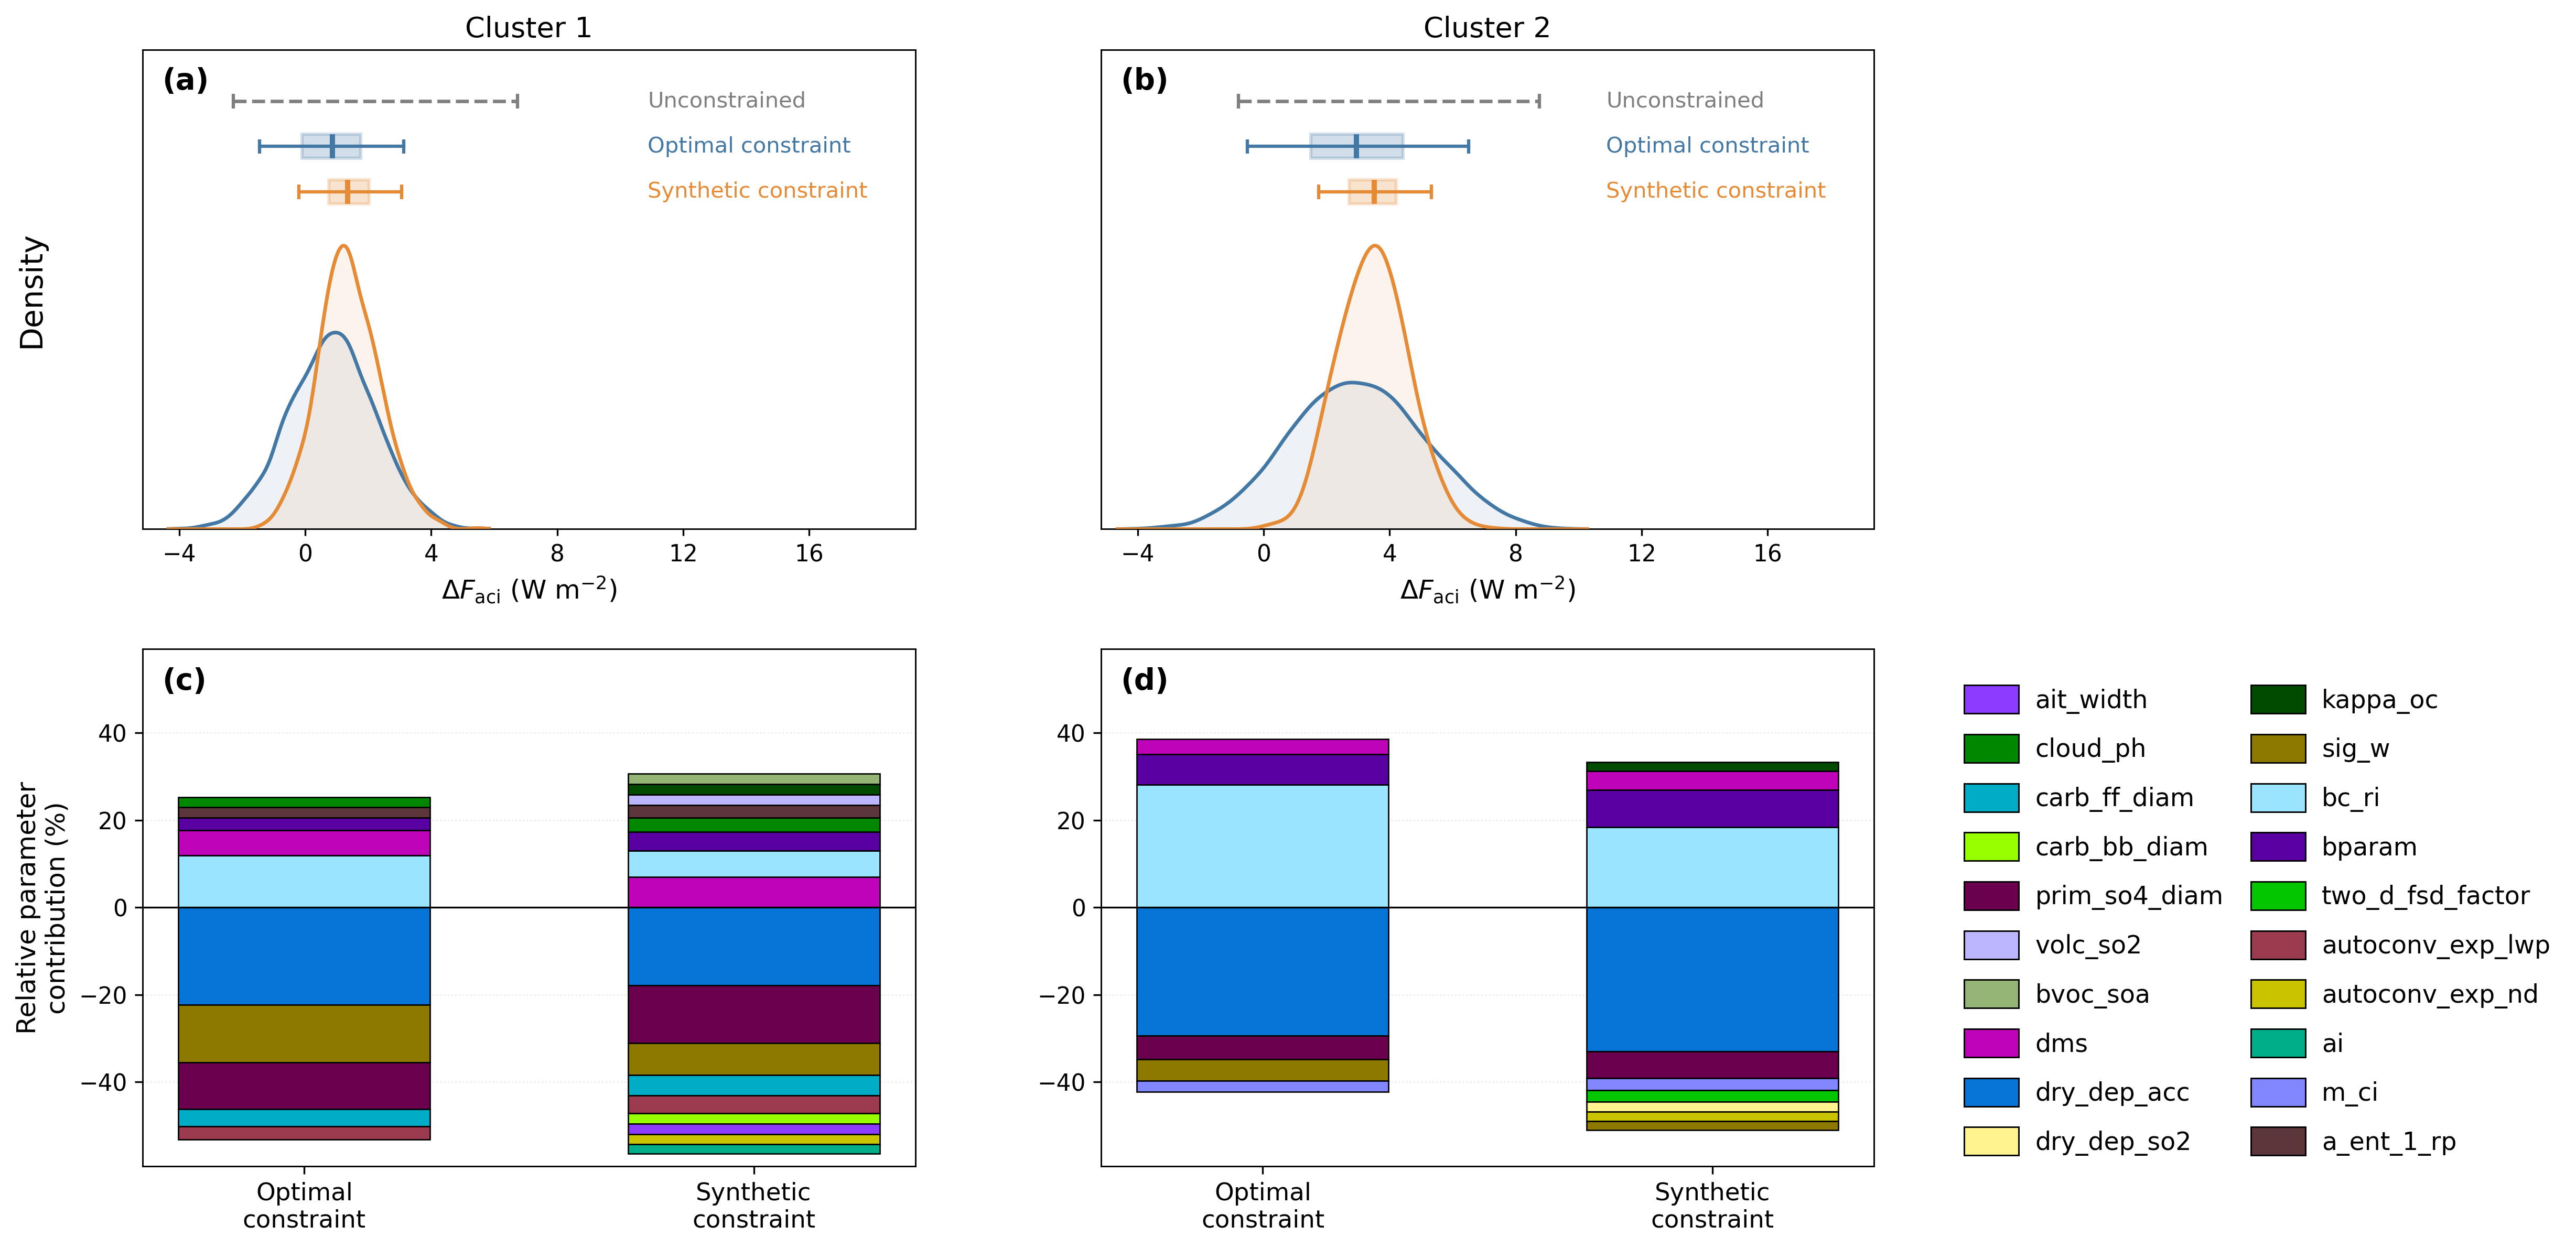

In [4]:
# ============================================================
# 10A. ANN FACI PDF + HORIZONTAL SUMMARIES + >2% PARAMETER FIGURE
#
# Upper row: Cluster 1 and Cluster 2
#   Unconstrained: horizontal P5-P95 line only (no PDF)
#   Optimal / Synthetic: overlapping PDFs and horizontal boxplots
#   Box: P25-P75; centre: P50; whiskers: P5-P95
#   The two clusters use the SAME forcing x-axis range.
#   Left-hand Density label enlarged, moved outward, and aligned with lower ylabel.
#
# Upper PDFs: no x=0 reference line.
# Lower row: original ANN >2% signed parameter contributions.
#   No repeated Cluster titles. Common x/y axis ranges;
#   tightened x-axis so bars occupy more of each panel. Two-column legend.
#
# Updated Fig. 4 method: average forcing over cluster gridpoints
# for EACH 1M variant FIRST, then subset variants and take percentiles.
# Run the updated Cell 1 before this cell.
# Display only: NO files are saved or modified.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import MaxNLocator

# ============================================================
# SETTINGS
# ============================================================

ann_clusters = ["c1", "c5"]
ann_threshold = 2.0

pdf_case_names = ["Optimal constraint", "Synthetic constraint"]
summary_case_names = [
    "Unconstrained",
    "Optimal constraint",
    "Synthetic constraint",
]
case_colors = {
    "Unconstrained": "#7F7F7F",
    "Optimal constraint": "#4378A5",
    "Synthetic constraint": "#E58A35",
}

panel_label_fontsize = 13.5
axis_label_fontsize = 12.0
tick_fontsize = 10.5
box_text_fontsize = 10.0

# ============================================================
# CHECK DEPENDENCIES CREATED BY CELL 1
# ============================================================

required_names = [
    "grouped_op", "grouped_final", "grid_df", "op_indices",
    "final_indices_by_cluster", "make_region_tag", "get_forcing_file",
    "sample_size_full", "parameter_names_subset", "param_color_dict",
    "cluster_title_map", "PRINT_MISSING_WARNINGS",
]
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise NameError(
        "Run the updated Cell 1 before Cell 2. Missing: "
        + ", ".join(missing_names)
    )

# ============================================================
# ANN >2% PARAMETER CONTRIBUTIONS (UNCHANGED CALCULATION)
# ============================================================

ann_gt2_op = grouped_op[
    (grouped_op["month"] == "ann")
    & grouped_op["cluster"].isin(ann_clusters)
    & (grouped_op["cluster_month_pct"] > ann_threshold)
].copy()

ann_gt2_final = grouped_final[
    (grouped_final["month"] == "ann")
    & grouped_final["cluster"].isin(ann_clusters)
    & (grouped_final["cluster_month_pct"] > ann_threshold)
].copy()

print("=" * 100)
print(f"ANN parameters with contribution > {ann_threshold:.1f}%")
print("=" * 100)
for name, data in [
    ("Optimal constrained", ann_gt2_op),
    ("Final synthetic constrained", ann_gt2_final),
]:
    print(f"\n{name}:")
    print(
        data[[
            "cluster", "month", "param", "cluster_month_pct",
            "signed_cluster_month_pct",
        ]].sort_values(
            ["cluster", "cluster_month_pct"], ascending=[True, False]
        ).to_string(index=False)
    )
print("")

# Common symmetric y-limits for all four bars.
ann_max_stack = 0.0
for cluster_code in ann_clusters:
    for table in (ann_gt2_op, ann_gt2_final):
        values = table.loc[
            table["cluster"] == cluster_code, "signed_cluster_month_pct"
        ].fillna(0.0).to_numpy(dtype=float)
        pos = values[values > 0].sum()
        neg = abs(values[values < 0].sum())
        ann_max_stack = max(ann_max_stack, pos, neg)
ann_bar_ylim = max(1.05 * ann_max_stack, 5.0)

# ============================================================
# ANN CLUSTER-MEAN FACI (UPDATED FIG. 4 ALGORITHM)
# Average gridpoints for each variant FIRST; percentiles SECOND.
# This is NOT mean(gridpoint CI90).
# ============================================================

def compute_ann_cluster_mean_faci(cluster_code, cluster_grid_df, op_idx, final_idx):
    forcing_sum = np.zeros(sample_size_full, dtype=float)
    n_grid_used = 0
    n_missing = 0

    for _, row in cluster_grid_df.iterrows():
        region = make_region_tag(
            cluster_code, row["_lat_dir_use"], row["_lon_dir_use"]
        )
        forcing_file = get_forcing_file("ann", region)
        if not os.path.exists(forcing_file):
            n_missing += 1
            if PRINT_MISSING_WARNINGS:
                print(f"Missing ANN forcing: {forcing_file}")
            continue

        try:
            var_full = np.asarray(
                np.loadtxt(forcing_file), dtype=float
            ).reshape(-1)
            if len(var_full) != sample_size_full:
                raise ValueError(
                    f"Expected {sample_size_full} values, got {len(var_full)}"
                )
            if not np.all(np.isfinite(var_full)):
                raise ValueError("NaN or infinity in ANN forcing")
        except Exception as error:
            n_missing += 1
            if PRINT_MISSING_WARNINGS:
                print(f"Cannot read {forcing_file}: {error}")
            continue

        forcing_sum += var_full
        n_grid_used += 1

    if n_grid_used == 0:
        raise ValueError(f"No valid ANN forcing gridpoints for {cluster_code}")

    cluster_mean_1m = forcing_sum / n_grid_used
    case_values = {
        "Unconstrained": cluster_mean_1m,
        "Optimal constraint": cluster_mean_1m[op_idx],
        "Synthetic constraint": cluster_mean_1m[final_idx],
    }

    case_stats = {}
    for case_name, arr in case_values.items():
        p5, p25, p50, p75, p95 = np.percentile(
            arr, [5, 25, 50, 75, 95]
        )
        case_stats[case_name] = {
            "p5": float(p5),
            "p25": float(p25),
            "p50": float(p50),
            "p75": float(p75),
            "p95": float(p95),
            "ci90": float(p95 - p5),
            "n": len(arr),
        }
    return case_values, case_stats, n_grid_used, n_missing


ann_faci_values = {}
ann_faci_stats = {}
print("=" * 100)
print("ANN cluster-mean FACI: spatial mean first, then P5/P25/P50/P75/P95")
print("=" * 100)
for cluster_code in ann_clusters:
    cluster_grid_df = grid_df[
        grid_df["_cluster_code"] == cluster_code
    ].copy()
    values, stats, n_used, n_missing = compute_ann_cluster_mean_faci(
        cluster_code, cluster_grid_df,
        op_indices, final_indices_by_cluster[cluster_code],
    )
    ann_faci_values[cluster_code] = values
    ann_faci_stats[cluster_code] = stats
    print(f"\n{cluster_title_map[cluster_code]}")
    for case_name in summary_case_names:
        s = stats[case_name]
        print(
            f"  {case_name:<22} "
            f"P5={s['p5']:9.4f}  P25={s['p25']:9.4f}  "
            f"P50={s['p50']:9.4f}  P75={s['p75']:9.4f}  "
            f"P95={s['p95']:9.4f}  CI90={s['ci90']:9.4f}  "
            f"n={s['n']}"
        )
    print(f"  Valid gridpoints: {n_used}; missing/invalid: {n_missing}")
print("")

# ============================================================
# KDE: SAME ABSOLUTE BANDWIDTH FOR OP AND SYNTHETIC, PER CLUSTER.
# Only OP and Synthetic have PDFs; 1M shows ONLY P5-P95.
# ============================================================

def make_kde_curves(case_values, n_x=500):
    op = np.asarray(case_values["Optimal constraint"], dtype=float)
    syn = np.asarray(case_values["Synthetic constraint"], dtype=float)
    values_all = np.concatenate([op, syn])
    x_low, x_high = np.percentile(values_all, [0.1, 99.9])
    span = float(x_high - x_low)
    if span <= 0:
        span = max(abs(float(x_low)) * 0.1, 0.1)
    x_grid = np.linspace(
        x_low - 0.12 * span, x_high + 0.12 * span, n_x
    )
    op_std = float(np.std(op, ddof=1))
    if op_std <= 0:
        raise ValueError("OP forcing distribution has zero variance; KDE undefined")
    bandwidth = op_std * (len(op) ** (-1.0 / 5.0))
    result = {}
    for name, data in [
        ("Optimal constraint", op),
        ("Synthetic constraint", syn),
    ]:
        data_std = float(np.std(data, ddof=1))
        if data_std <= 0:
            raise ValueError(f"{name} forcing distribution has zero variance")
        kde = gaussian_kde(data, bw_method=bandwidth / data_std)
        result[name] = kde(x_grid)
    return x_grid, result

# ============================================================
# PLOT HELPERS
# ============================================================

def draw_horizontal_p50_box(ax, xstats, y, color, height):
    """P5-P95 whiskers, P25-P75 box, P50 (median) centre line."""
    p5, p25, p50, p75, p95 = (
        xstats["p5"], xstats["p25"], xstats["p50"],
        xstats["p75"], xstats["p95"],
    )
    ax.plot([p5, p95], [y, y], color=color, linewidth=1.5, zorder=6)
    cap_height = height * 0.60
    ax.vlines(
        [p5, p95], y - cap_height / 2, y + cap_height / 2,
        colors=color, linewidth=1.5, zorder=7,
    )
    ax.add_patch(Rectangle(
        (p25, y - height / 2), p75 - p25, height,
        facecolor=color, edgecolor=color, alpha=0.24,
        linewidth=1.5, zorder=8,
    ))
    ax.vlines(
        p50, y - height / 2, y + height / 2,
        colors=color, linewidth=2.4, zorder=9,
    )


def draw_horizontal_p5_p95_line(ax, xstats, y, color, cap_height):
    """Unconstrained: dashed P5-P95 range only, with short end caps."""
    ax.plot(
        [xstats["p5"], xstats["p95"]], [y, y],
        color=color, linewidth=1.6, linestyle="--", zorder=6,
    )
    ax.vlines(
        [xstats["p5"], xstats["p95"]],
        y - cap_height / 2, y + cap_height / 2,
        colors=color, linewidth=1.5, zorder=7,
    )


def draw_signed_parameter_bar(ax, data, xpos, bar_width=0.56):
    """Original ANN >2% signed contribution and parameter colors."""
    pos_bottom, neg_bottom = 0.0, 0.0
    sub = data.sort_values("cluster_month_pct", ascending=False)
    for _, row in sub.iterrows():
        value = float(row["signed_cluster_month_pct"])
        color = param_color_dict.get(row["param"], "#808080")
        if value >= 0:
            bottom = pos_bottom
            pos_bottom += value
        else:
            bottom = neg_bottom
            neg_bottom += value
        ax.bar(
            xpos, value, width=bar_width, bottom=bottom,
            color=color, edgecolor="black", linewidth=0.65, zorder=3,
        )

# ============================================================
# COMPUTE COMMON UPPER X-LIMITS FOR THE TWO CLUSTERS
# (include both KDE curves AND 1M P5-P95 endpoints)
# ============================================================

ann_kde_by_cluster = {}
x_limits_candidates = []
for cluster_code in ann_clusters:
    grid_x, pdf_curves = make_kde_curves(ann_faci_values[cluster_code])
    ann_kde_by_cluster[cluster_code] = (grid_x, pdf_curves)
    x_limits_candidates.extend([
        float(grid_x[0]), float(grid_x[-1]),
        ann_faci_stats[cluster_code]["Unconstrained"]["p5"],
        ann_faci_stats[cluster_code]["Unconstrained"]["p95"],
    ])

common_data_left = min(x_limits_candidates)
common_data_right = max(x_limits_candidates)
common_span = common_data_right - common_data_left
if common_span <= 0:
    common_span = max(0.2 * abs(common_data_left), 1.0)

# Make a common label zone on the RIGHT of the data in each upper panel.
label_x = common_data_right + 0.04 * common_span
common_xlim = (
    common_data_left - 0.035 * common_span,
    common_data_right + 0.61 * common_span,
)
# Show x-axis ticks across the ENTIRE displayed axis, including the label area.
common_force_xticks = [
    float(t) for t in MaxNLocator(nbins=7).tick_values(
        common_xlim[0], common_xlim[1]
    )
    if common_xlim[0] <= t <= common_xlim[1]
]

# ============================================================
# LAYOUT: 2x2; wide enough for a two-column parameter legend.
# ============================================================

fig = plt.figure(figsize=(17.2, 8.45), dpi=300)
gs = fig.add_gridspec(
    2, 2, height_ratios=[1.00, 1.08], hspace=0.24, wspace=0.24,
)
axes_top = {
    "c1": fig.add_subplot(gs[0, 0]),
    "c5": fig.add_subplot(gs[0, 1]),
}
axes_bottom = {
    "c1": fig.add_subplot(gs[1, 0]),
    "c5": fig.add_subplot(gs[1, 1]),
}

# ============================================================
# UPPER: OP / SYN PDFs + THREE HORIZONTAL SUMMARIES
# ============================================================

for panel_i, cluster_code in enumerate(ann_clusters):
    ax = axes_top[cluster_code]
    stats = ann_faci_stats[cluster_code]
    x_grid, curves = ann_kde_by_cluster[cluster_code]
    density_max = max(float(np.max(curves[name])) for name in pdf_case_names)

    for case_name in pdf_case_names:
        color = case_colors[case_name]
        density = curves[case_name]
        ax.fill_between(
            x_grid, 0, density, color=color, alpha=0.09, zorder=2,
        )
        ax.plot(
            x_grid, density, color=color, linewidth=1.65, zorder=3,
        )

    # Slightly closer rows, but all remain safely above the PDF peak.
    summary_y = {
        "Unconstrained": 1.51 * density_max,
        "Optimal constraint": 1.35 * density_max,
        "Synthetic constraint": 1.19 * density_max,
    }
    box_height = 0.085 * density_max

    draw_horizontal_p5_p95_line(
        ax, stats["Unconstrained"], summary_y["Unconstrained"],
        case_colors["Unconstrained"], box_height * 0.60,
    )
    for case_name in pdf_case_names:
        draw_horizontal_p50_box(
            ax, stats[case_name], summary_y[case_name],
            case_colors[case_name], box_height,
        )

    for case_name in summary_case_names:
        ax.text(
            label_x, summary_y[case_name], case_name,
            color=case_colors[case_name], ha="left", va="center",
            fontsize=box_text_fontsize, fontweight="medium",
        )

    ax.set_xlim(*common_xlim)  # SAME x-range for c1 and c5.
    ax.set_xticks(common_force_xticks)
    ax.set_ylim(0, 1.69 * density_max)
    ax.set_xlabel(
        r"$\Delta F_{\mathrm{aci}}$ (W m$^{-2}$)",
        fontsize=axis_label_fontsize,
    )
    if panel_i == 0:
        ax.set_ylabel("Density", fontsize=14.0, labelpad=15)
    else:
        ax.set_ylabel("")
    ax.set_yticks([])  # Keep the Density label but no y-axis ticks.
    ax.tick_params(axis="y", left=False, labelleft=False)
    ax.tick_params(
        axis="x", labelsize=tick_fontsize, direction="out", length=3,
    )
    ax.set_title(cluster_title_map[cluster_code], fontsize=13.0, pad=6)
    ax.text(
        0.025, 0.965, f"({chr(97 + panel_i)})",
        transform=ax.transAxes, va="top", ha="left",
        fontsize=panel_label_fontsize, fontweight="bold",
    )

# ============================================================
# LOWER: UNCHANGED ANN >2% SIGNED PARAMETER BARS
# ============================================================

appeared_parameters = set()
for panel_i, cluster_code in enumerate(ann_clusters):
    ax = axes_bottom[cluster_code]
    sub_op = ann_gt2_op[ann_gt2_op["cluster"] == cluster_code].copy()
    sub_final = ann_gt2_final[
        ann_gt2_final["cluster"] == cluster_code
    ].copy()

    draw_signed_parameter_bar(ax, sub_op, xpos=0.0)
    draw_signed_parameter_bar(ax, sub_final, xpos=1.0)

    ax.axhline(0, color="black", linewidth=0.8, zorder=4)
    ax.set_ylim(-ann_bar_ylim, ann_bar_ylim)
    # Tight, identical x-axis limits: two bars fill more of each panel.
    ax.set_xlim(-0.36, 1.36)
    ax.set_xticks([0.0, 1.0])
    ax.set_xticklabels(
        ["Optimal\nconstraint", "Synthetic\nconstraint"], fontsize=11.2,
    )
    ax.tick_params(axis="y", labelsize=tick_fontsize)
    ax.grid(axis="y", linestyle=":", linewidth=0.65, alpha=0.27, zorder=0)
    if panel_i == 0:
        ax.set_ylabel(
            "Relative parameter\ncontribution (%)", fontsize=axis_label_fontsize,
        )
    # No repeated Cluster 1 / Cluster 2 lower titles.
    ax.set_title("")
    ax.text(
        0.025, 0.965, f"({chr(99 + panel_i)})",
        transform=ax.transAxes, va="top", ha="left",
        fontsize=panel_label_fontsize, fontweight="bold",
    )
    appeared_parameters.update(sub_op["param"].dropna().unique())
    appeared_parameters.update(sub_final["param"].dropna().unique())

# ============================================================
# TWO-COLUMN PARAMETER LEGEND, LARGE PATCHES AND FONTS
# ============================================================

legend_params = [
    p for p in parameter_names_subset if p in appeared_parameters
]
print("Parameters appearing in ANN >2% bars:")
print(", ".join(legend_params))
legend_handles = [
    Patch(
        facecolor=param_color_dict[p], edgecolor="black",
        linewidth=0.7, label=p,
    )
    for p in legend_params
]
if legend_handles:
    fig.legend(
        handles=legend_handles,
        loc="center left", bbox_to_anchor=(0.74, 0.29),
        ncol=2, frameon=False, fontsize=11.4,
        handlelength=2.20, handleheight=1.38,
        handletextpad=0.65, columnspacing=1.10, labelspacing=0.83,
    )

fig.subplots_adjust(
    left=0.075, right=0.715, top=0.945, bottom=0.105,
)

# Align the left-hand y-axis labels in the upper and lower panels.
fig.align_ylabels([axes_top["c1"], axes_bottom["c1"]])

# Notebook display only. DO NOT save any image, CSV, or other files.
plt.show()
